<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/adi-e2/notebooks/gsm8k/E2_Experiment_SRIG_Eval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# Experiment 2: Two-Step Lookahead MEDAL vs. AB-MEDAL on GSM8K with Sum of Relative Information Gains (SRIG) — Evaluation (20 Canonical + 50 Extended Questions)

This notebook runs **Experiment 2 (E2)** on the GSM8K validation/evaluation pool with `LLaDA-8B-Instruct` using the **Two-Step Sum of Relative Information Gains (SRIG / $\text{Future}R_{ig}$)** reward function:
$$
\text{Future}R_{ig}(s, a_i) = R_{ig}(s, s_i) + \lambda \, R_{ig}(s_i, g_i^*) = \frac{H(s) - H(s_i)}{\max(H(s), \epsilon)} + \lambda \frac{H(s_i) - H(g_i^*)}{\max(H(s_i), \epsilon)}
$$

### Dataset Split Organization:
1. **Canonical 20 Samples** (`sample_slice=(0, 20)`): The exact 20 evaluation questions from Experiment 1, preserving historical prefix ordering.
2. **Additional 50 Samples** (`sample_slice=(20, 70)`): 50 new validation questions sampled under the deterministic `sample_seed=1` order.
3. **Combined 70 Samples**: Full validation pool evaluation and paired statistical tests.

### Guardrails & Protocols:
- Capped at $4B$ simulations per question as an exploration runaway safeguard; actual NFE utilization is logged.
- Virtual grandchildren are evaluated and cached in `cached_analyses` but never attached to the tree or assigned GEN/CONT posteriors.
- Non-mutating hypothetical boundary snapshots ensure standalone $B=256$ equivalence without altering live tree execution toward $B=512$.


## 1. Verify GPU Hardware
Verify CUDA GPU supporting bfloat16 (recommended: L4 or A100 with $\ge 22$ GiB VRAM).

In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError('Select a CUDA GPU runtime in Colab (L4 or A100), then reconnect.')
gpu = torch.cuda.get_device_properties(0)
vram_gb = gpu.total_memory / (1024 ** 3)
print(f'GPU: {gpu.name} | Total VRAM: {vram_gb:.2f} GiB')


GPU: NVIDIA L4 | Total VRAM: 22.03 GiB


## 2. Repository Setup
Clone or update the GitHub repository on branch `adi-e2`.

In [2]:
from pathlib import Path
import os
import subprocess
import sys

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/CooL-Legend/CSCI544-DLM.git'
BRANCH = 'adi-e2'
REPO_DIR = Path('/content/CSCI544-DLM') if IN_COLAB else Path.cwd().resolve()

if IN_COLAB:
    if not (REPO_DIR / '.git').exists():
        token = os.environ.get('GITHUB_TOKEN', '')
        if not token:
            try:
                from google.colab import userdata
                token = userdata.get('GITHUB_TOKEN')
            except Exception:
                pass
        clone_url = REPO_URL.replace('https://', f'https://{token}@') if token else REPO_URL
        subprocess.run(['git', 'clone', '-b', BRANCH, clone_url, str(REPO_DIR)], check=True)
    else:
        subprocess.run(['git', '-C', str(REPO_DIR), 'fetch', 'origin', BRANCH], check=True)
        subprocess.run(['git', '-C', str(REPO_DIR), 'checkout', BRANCH], check=True)
        subprocess.run(['git', '-C', str(REPO_DIR), 'pull', 'origin', BRANCH], check=True)
    os.chdir(REPO_DIR)
    if str(REPO_DIR / 'src') not in sys.path:
        sys.path.insert(0, str(REPO_DIR / 'src'))

print(f'Working directory: {Path.cwd()}')


Working directory: /content/CSCI544-DLM


## 3. Install Dependencies
Install pinned dependencies and editable package.

In [3]:
import site
import subprocess
import sys

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(REPO_DIR / 'requirements/llada-colab.txt')], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO_DIR)], check=True)
    import importlib
    importlib.invalidate_caches()
    user_site = site.getusersitepackages()
    if user_site not in sys.path:
        sys.path.append(user_site)
print('Dependencies installed successfully.')


Dependencies installed successfully.


## 4. Run Algorithmic Pre-Flight Unit Tests
Verify 2-step lookahead SRIG reward computation, state caching, and batched parity before loading weights.

In [4]:
import subprocess
import sys

res = subprocess.run(
    [sys.executable, '-m', 'pytest', 'tests/tasks/test_experiment_2.py', '-v'],
    capture_output=True, text=True
)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Pre-flight E2 unit tests failed!')
print('All E2 algorithmic unit tests passed.')


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/CSCI544-DLM
configfile: pyproject.toml
plugins: langsmith-0.14.17, anyio-4.16.0, platformdirs-4.14.3, typeguard-4.6.0
collecting ... collected 13 items

tests/tasks/test_experiment_2.py::test_fig_reward_formula PASSED         [  7%]
tests/tasks/test_experiment_2.py::test_srig_reward_formula PASSED        [ 15%]
tests/tasks/test_experiment_2.py::test_e2_context_and_manifest_slicing PASSED [ 23%]
tests/tasks/test_experiment_2.py::test_e2_search_two_step_step_execution[medal] PASSED [ 30%]
tests/tasks/test_experiment_2.py::test_e2_search_two_step_step_execution[ab_medal] PASSED [ 38%]
tests/tasks/test_experiment_2.py::test_e2_grandchild_cache_reuse PASSED  [ 46%]
tests/tasks/test_experiment_2.py::test_e2_batched_parity_with_serial PASSED [ 53%]
tests/tasks/test_experiment_2.py::test_e2_st

## 5. Mount Google Drive & Configure Cache
Mount Google Drive for persistent artifact and model caching.

In [5]:
from pathlib import Path
import os

DRIVE_ROOT = Path('/content/drive/MyDrive/CSCI544-DLM')
OUTPUT_DIR = Path('results/e2_srig_eval')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = DRIVE_ROOT / 'results/e2_srig_eval'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    cache_dir = DRIVE_ROOT / 'cache/huggingface'
    cache_dir.mkdir(parents=True, exist_ok=True)
    os.environ['HF_HOME'] = str(cache_dir)
    os.environ['HUGGINGFACE_HUB_CACHE'] = str(cache_dir)

print(f'Output directory: {OUTPUT_DIR.resolve()}')


Mounted at /content/drive
Output directory: /content/drive/MyDrive/CSCI544-DLM/results/e2_srig_eval


## 6. Experiment Controls & Staged Model Loading
Configure budgets [256, 512], depth 10, batch size 2, SRIG reward mode, and load `LLaDA-8B-Instruct` from staged NVMe storage.

In [6]:
import shutil
from pathlib import Path
from dlm_project.models.profiles import get_profile
from dlm_project.tasks.gsm8k.experiment_2 import (
    CHECKPOINT_BUDGETS, MAX_SEARCH_DEPTH, MIN_CANDIDATES, context, load_model
)

STAGE = 'evaluation'
METHODS = ('medal', 'ab_medal')
BUDGETS = (256, 512)
REWARD_MODE = 'srig'
REWARD_LAMBDA = 1.0
SIM_CAP_MULTIPLIER = 4
# On NVIDIA L4 (22.4 GiB VRAM), BATCH_SIZE = 2 is recommended for stability;
# BATCH_SIZE = 4 is suited for A100 (40/80 GB) or High-RAM runtimes.
BATCH_SIZE = 4
RESUME = True

# Load base context to initialize model identity
base_ctx = context(
    stage='evaluation',
    methods=METHODS,
    budgets=BUDGETS,
    reward_mode=REWARD_MODE,
    reward_lambda=REWARD_LAMBDA,
    sim_cap_multiplier=SIM_CAP_MULTIPLIER,
)

profile = get_profile('llada')
model_name = profile['repo_id'].split('/')[-1]
drive_model_dir = DRIVE_ROOT / 'models' / model_name
runtime_model_dir = Path('/content/models') / model_name

# Fast local NVMe cache in Colab runtime if available on Drive
if IN_COLAB and drive_model_dir.is_dir() and not (runtime_model_dir / 'config.json').is_file():
    print(f'Copying model from Google Drive to local fast runtime storage: {runtime_model_dir}...')
    shutil.copytree(drive_model_dir, runtime_model_dir)

MODEL_PATH = str(runtime_model_dir if runtime_model_dir.is_dir() else (drive_model_dir if drive_model_dir.is_dir() else profile['repo_id']))
print('Using model location:', MODEL_PATH)
print('Loading LLaDA-8B-Instruct wrapper on GPU in bfloat16...')
wrapper = load_model(base_ctx, model_path=MODEL_PATH, device='cuda', local_files_only=Path(MODEL_PATH).is_dir())
print(f'✓ Model loaded: {wrapper.identity["family"]} ({wrapper.identity["repo_id"]} @ {wrapper.identity["revision"]})')


Copying model from Google Drive to local fast runtime storage: /content/models/LLaDA-8B-Instruct...
Using model location: /content/models/LLaDA-8B-Instruct
Loading LLaDA-8B-Instruct wrapper on GPU in bfloat16...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

✓ Model loaded: llada (GSAI-ML/LLaDA-8B-Instruct @ 08b83a6feb34df1a6011b80c3c00c7563e963b07)


## 7. Execute Part 1: Canonical Evaluation Set (Original 20 Questions)
Evaluates the exact 20 evaluation questions from Experiment 1 (`sample_slice=(0, 20)`).

In [7]:
from time import perf_counter
from dlm_project.tasks.gsm8k.experiment_2 import run_e2_stage

ctx_20 = context(
    stage='evaluation',
    methods=METHODS,
    budgets=BUDGETS,
    sample_slice=(0, 20)
    reward_mode=REWARD_MODE,
    reward_lambda=REWARD_LAMBDA,
    sim_cap_multiplier=SIM_CAP_MULTIPLIER,
)
print(f'Starting Part 1 (Canonical 20 Questions) with SRIG reward...')
t0 = perf_counter()
q_rows_20, agg_rows_20 = run_e2_stage(
    wrapper,
    ctx_20,
    OUTPUT_DIR / 'canonical_20',
    methods=METHODS,
    budgets=BUDGETS,
    max_depth=MAX_SEARCH_DEPTH,
    num_candidates=MIN_CANDIDATES,
    resume=RESUME,
    batch_size=BATCH_SIZE,
)
print(f'Part 1 Complete in {(perf_counter() - t0) / 60:.2f} minutes.')


Starting Part 1 (Canonical 20 Questions) with SRIG reward...

[Progress 1-4/20 | batch_size=4] Questions: train:4222, train:3588, train:5224, train:2620 | Model: MEDAL
  [MEDAL Step 1] Active: 4/4 | Q0:0/512 NFEs, 0/2048 sims (1 nodes), Q1:0/512 NFEs, 0/2048 sims (1 nodes), Q2:0/512 NFEs, 0/2048 sims (1 nodes), Q3:0/512 NFEs, 0/2048 sims (1 nodes)
  [MEDAL Step 25] Active: 4/4 | Q0:24/512 NFEs, 14/2048 sims (16 nodes), Q1:24/512 NFEs, 16/2048 sims (18 nodes), Q2:24/512 NFEs, 16/2048 sims (18 nodes), Q3:24/512 NFEs, 14/2048 sims (16 nodes)
  [MEDAL Step 50] Active: 4/4 | Q0:49/512 NFEs, 32/2048 sims (34 nodes), Q1:49/512 NFEs, 32/2048 sims (34 nodes), Q2:49/512 NFEs, 34/2048 sims (36 nodes), Q3:49/512 NFEs, 39/2048 sims (41 nodes)
  [MEDAL Step 75] Active: 4/4 | Q0:74/512 NFEs, 53/2048 sims (55 nodes), Q1:74/512 NFEs, 58/2048 sims (60 nodes), Q2:74/512 NFEs, 67/2048 sims (69 nodes), Q3:74/512 NFEs, 57/2048 sims (59 nodes)
  [MEDAL Step 100] Active: 4/4 | Q0:99/512 NFEs, 104/2048 sims (1

## 8. Execute Part 2: Extended Validation Set (Additional 50 Questions)
Evaluates the additional 50 validation questions (`sample_slice=(20, 70)`).

In [8]:
ctx_50 = context(
    stage='evaluation',
    methods=METHODS,
    budgets=BUDGETS,
    sample_slice=(20, 70),
    reward_mode=REWARD_MODE,
    reward_lambda=REWARD_LAMBDA,
    sim_cap_multiplier=SIM_CAP_MULTIPLIER,
)
print(f'Starting Part 2 (Additional 50 Questions) with SRIG reward...')
t0 = perf_counter()
q_rows_50, agg_rows_50 = run_e2_stage(
    wrapper,
    ctx_50,
    OUTPUT_DIR / 'extended_50',
    methods=METHODS,
    budgets=BUDGETS,
    max_depth=MAX_SEARCH_DEPTH,
    num_candidates=MIN_CANDIDATES,
    resume=RESUME,
    batch_size=BATCH_SIZE,
)
print(f'Part 2 Complete in {(perf_counter() - t0) / 60:.2f} minutes.')


Starting Part 2 (Additional 50 Questions) with SRIG reward...

[Progress 1-4/50 | batch_size=4] Questions: train:4909, train:5462, train:4895, train:7065 | Model: MEDAL
  [MEDAL Step 1] Active: 4/4 | Q0:0/512 NFEs, 0/2048 sims (1 nodes), Q1:0/512 NFEs, 0/2048 sims (1 nodes), Q2:0/512 NFEs, 0/2048 sims (1 nodes), Q3:0/512 NFEs, 0/2048 sims (1 nodes)
  [MEDAL Step 25] Active: 4/4 | Q0:24/512 NFEs, 14/2048 sims (16 nodes), Q1:24/512 NFEs, 14/2048 sims (16 nodes), Q2:24/512 NFEs, 14/2048 sims (16 nodes), Q3:24/512 NFEs, 16/2048 sims (18 nodes)
  [MEDAL Step 50] Active: 4/4 | Q0:49/512 NFEs, 42/2048 sims (44 nodes), Q1:49/512 NFEs, 35/2048 sims (37 nodes), Q2:49/512 NFEs, 30/2048 sims (32 nodes), Q3:49/512 NFEs, 36/2048 sims (38 nodes)
  [MEDAL Step 75] Active: 4/4 | Q0:74/512 NFEs, 79/2048 sims (81 nodes), Q1:74/512 NFEs, 61/2048 sims (63 nodes), Q2:74/512 NFEs, 49/2048 sims (51 nodes), Q3:74/512 NFEs, 56/2048 sims (58 nodes)
  [MEDAL Step 100] Active: 4/4 | Q0:99/512 NFEs, 109/2048 sims (

## 9. Results & Paired Comparisons (Canonical 20, Extended 50, and Combined 70)

In [9]:
import pandas as pd
from IPython.display import display
from scripts.run_e2 import compute_paired_comparison
from dlm_project.experiments.sweep_report import write_csv

summaries_dir = OUTPUT_DIR / 'summaries'
summaries_dir.mkdir(parents=True, exist_ok=True)

print('=== Part 1: Canonical 20 Questions Paired Comparison ===')
paired_20 = compute_paired_comparison(q_rows_20, budgets=BUDGETS)
if paired_20:
    df_p20 = pd.DataFrame(paired_20)[['search_budget', 'paired_questions', 'medal_accuracy', 'ab_medal_accuracy', 'accuracy_delta_percent', 'ab_medal_only_correct', 'medal_only_correct', 'mcnemar_exact_p']]
    display(df_p20)
    write_csv(summaries_dir / 'e2_srig_canonical_20_paired_comparison.csv', paired_20)

print('=== Part 2: Additional 50 Questions Paired Comparison ===')
paired_50 = compute_paired_comparison(q_rows_50, budgets=BUDGETS)
if paired_50:
    df_p50 = pd.DataFrame(paired_50)[['search_budget', 'paired_questions', 'medal_accuracy', 'ab_medal_accuracy', 'accuracy_delta_percent', 'ab_medal_only_correct', 'medal_only_correct', 'mcnemar_exact_p']]
    display(df_p50)
    write_csv(summaries_dir / 'e2_srig_extended_50_paired_comparison.csv', paired_50)

print('=== Combined Pool (All 70 Questions) Paired Comparison ===')
combined_q_rows = q_rows_20 + q_rows_50
paired_combined = compute_paired_comparison(combined_q_rows, budgets=BUDGETS)
if paired_combined:
    df_pcomb = pd.DataFrame(paired_combined)[['search_budget', 'paired_questions', 'medal_accuracy', 'ab_medal_accuracy', 'accuracy_delta_percent', 'ab_medal_only_correct', 'medal_only_correct', 'mcnemar_exact_p']]
    display(df_pcomb)
    write_csv(summaries_dir / 'e2_srig_combined_70_paired_comparison.csv', paired_combined)
    write_csv(summaries_dir / 'e2_srig_evaluation_paired_comparison.csv', paired_combined)


=== Part 1: Canonical 20 Questions Paired Comparison ===


,search_budget,paired_questions,medal_accuracy,ab_medal_accuracy,accuracy_delta_percent,ab_medal_only_correct,medal_only_correct,mcnemar_exact_p
0,256,20,0.4,0.3,-10.0,1,3,0.625
1,512,20,0.3,0.4,10.0,3,1,0.625


=== Part 2: Additional 50 Questions Paired Comparison ===


,search_budget,paired_questions,medal_accuracy,ab_medal_accuracy,accuracy_delta_percent,ab_medal_only_correct,medal_only_correct,mcnemar_exact_p
0,256,50,0.54,0.64,10.0,5,0,0.0625
1,512,50,0.58,0.56,-2.0,7,8,1.0000


=== Combined Pool (All 70 Questions) Paired Comparison ===


,search_budget,paired_questions,medal_accuracy,ab_medal_accuracy,accuracy_delta_percent,ab_medal_only_correct,medal_only_correct,mcnemar_exact_p
0,256,70,0.5,0.542857,4.285714,6,3,0.507812
1,512,70,0.5,0.514286,1.428571,10,9,1.000000


## 10. Interactive Search Tree & Decision Trace Inspector
Inspect the search tree topology, candidate nodes, and decision trace for any evaluated question.

In [11]:
from dlm_project.tasks.gsm8k.tree_viz import print_ascii_tree, summarize_decision_trace
import json

# Select a sample question to inspect from canonical_20
sample_ex_id = ctx_20['examples'][0]['example_id']
chk_dir = OUTPUT_DIR / 'canonical_20' / 'evaluation' / 'ab_medal' / sample_ex_id / 'checkpoints/256'
tree_json = chk_dir / 'tree.json'
metrics_json = chk_dir / 'metrics.json'

if tree_json.is_file():
    print(f'=== AB-MEDAL Search Tree at B=256 for {sample_ex_id} ===')
    print(print_ascii_tree(tree_json, max_depth=5, max_children_per_node=3))

if metrics_json.is_file():
    met = json.loads(metrics_json.read_text())
    print(f'=== Checkpoint Metrics ({sample_ex_id} @ B=256) ===')
    print(f'  Selected Node: {met["selected_node_id"]} | Depth: {met["selected_depth"]} | Q: {met["selected_q"]:.4f}')
    print(f'  Exact Match: {met["exact_match"]} | Pred: {met["predicted_answer"]} | Ref: {met["reference_answer"]}')
    print(f'  NFE Utilization: {met.get("nfe_utilization", 1.0)*100:.1f}% | Sims: {met.get("simulations_completed", "N/A")}/{met.get("simulation_cap", "N/A")}')


ModuleNotFoundError: No module named 'dlm_project.tasks.gsm8k.tree_viz'

## 11. E3 Offline Metric Extraction & Publication Figures
Run offline tree allocation, branching dynamics, and structural analysis on saved evaluation checkpoints (zero GPU compute), and generate 6 publication figures.

Running E3 Offline Tree Analysis on /content/drive/MyDrive/CSCI544-DLM/results/e2_srig_eval/combined_70/evaluation...
E3 offline analysis complete: saved /content/drive/MyDrive/CSCI544-DLM/results/e2_srig_eval/combined_70/summaries/e3_evaluation_per_question.csv, /content/drive/MyDrive/CSCI544-DLM/results/e2_srig_eval/combined_70/summaries/e3_evaluation_aggregate.csv, and figures to /content/drive/MyDrive/CSCI544-DLM/results/e2_srig_eval/combined_70/summaries/e3_figures
✓ E3 Analysis Completed successfully: 280 question outcomes evaluated.


### Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets

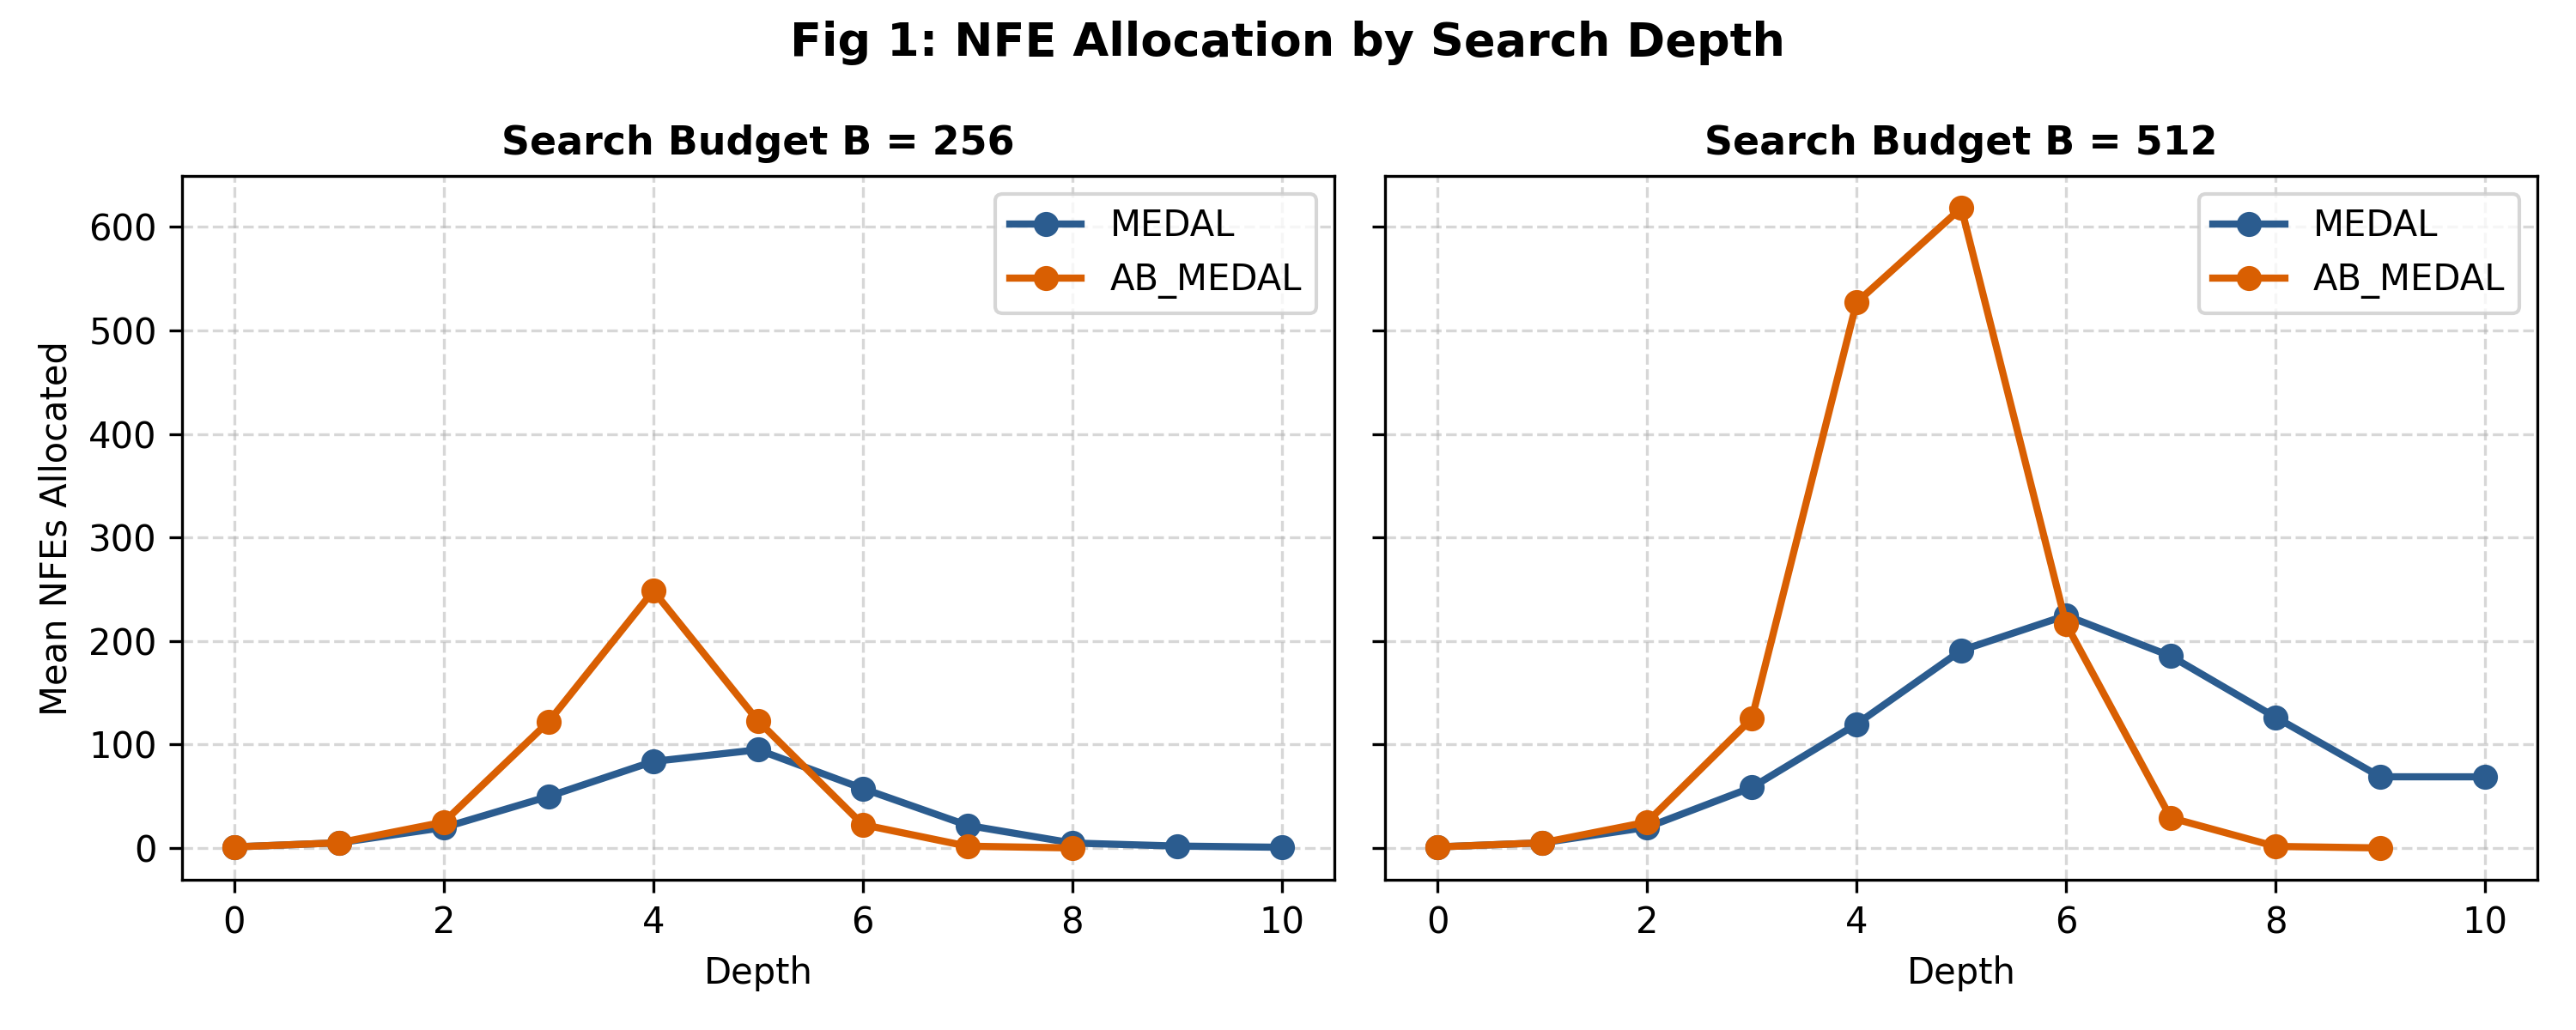

### Figure 2: Branching Factor Distribution — Children per expanded parent

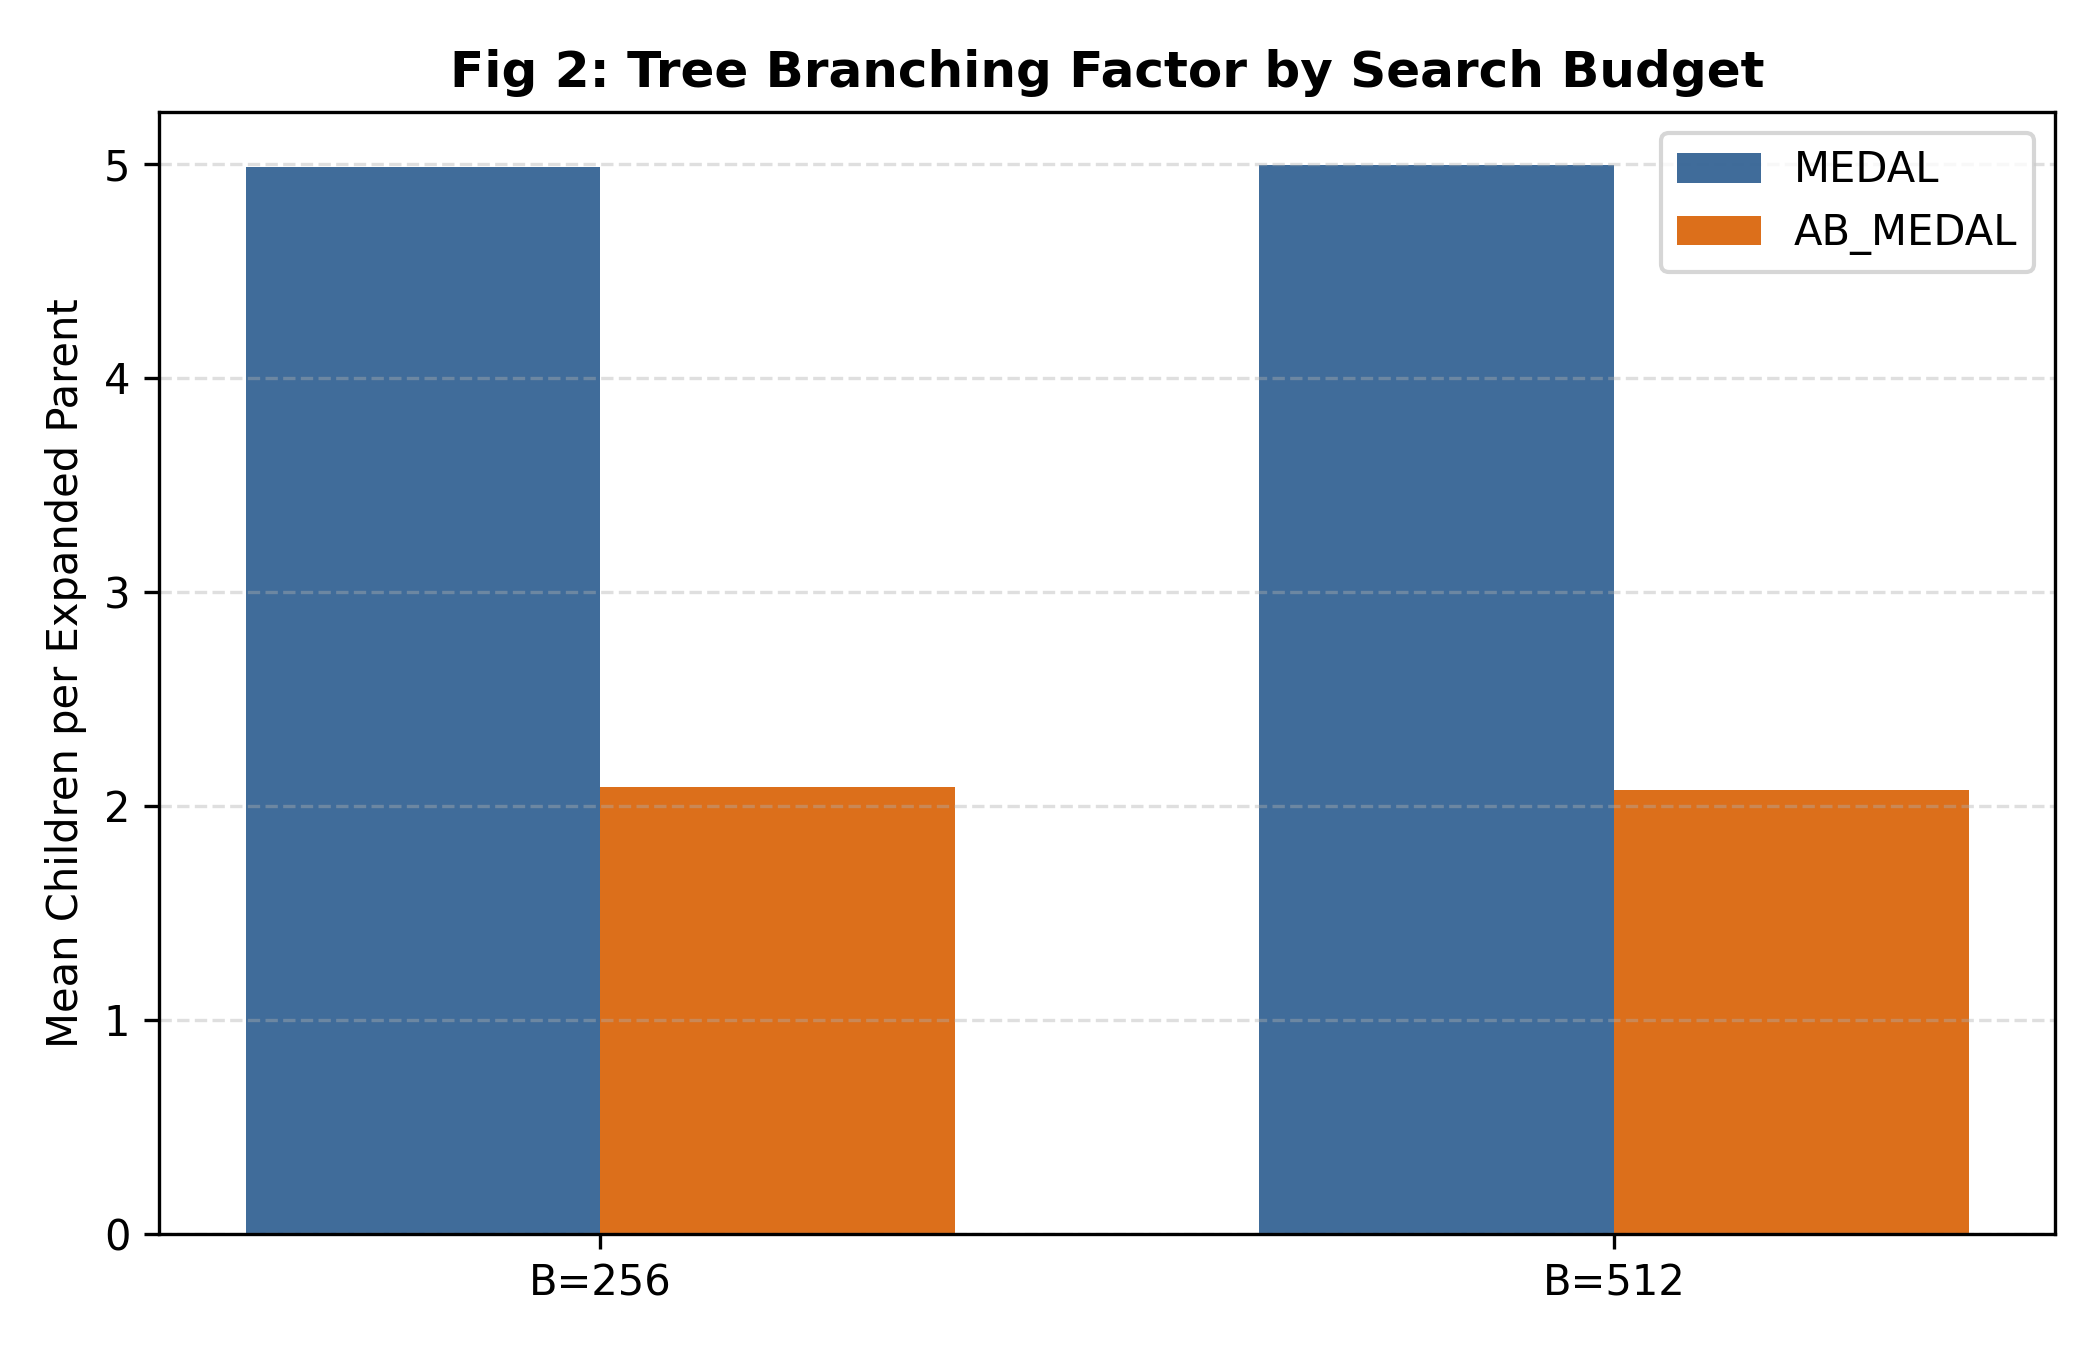

### Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth

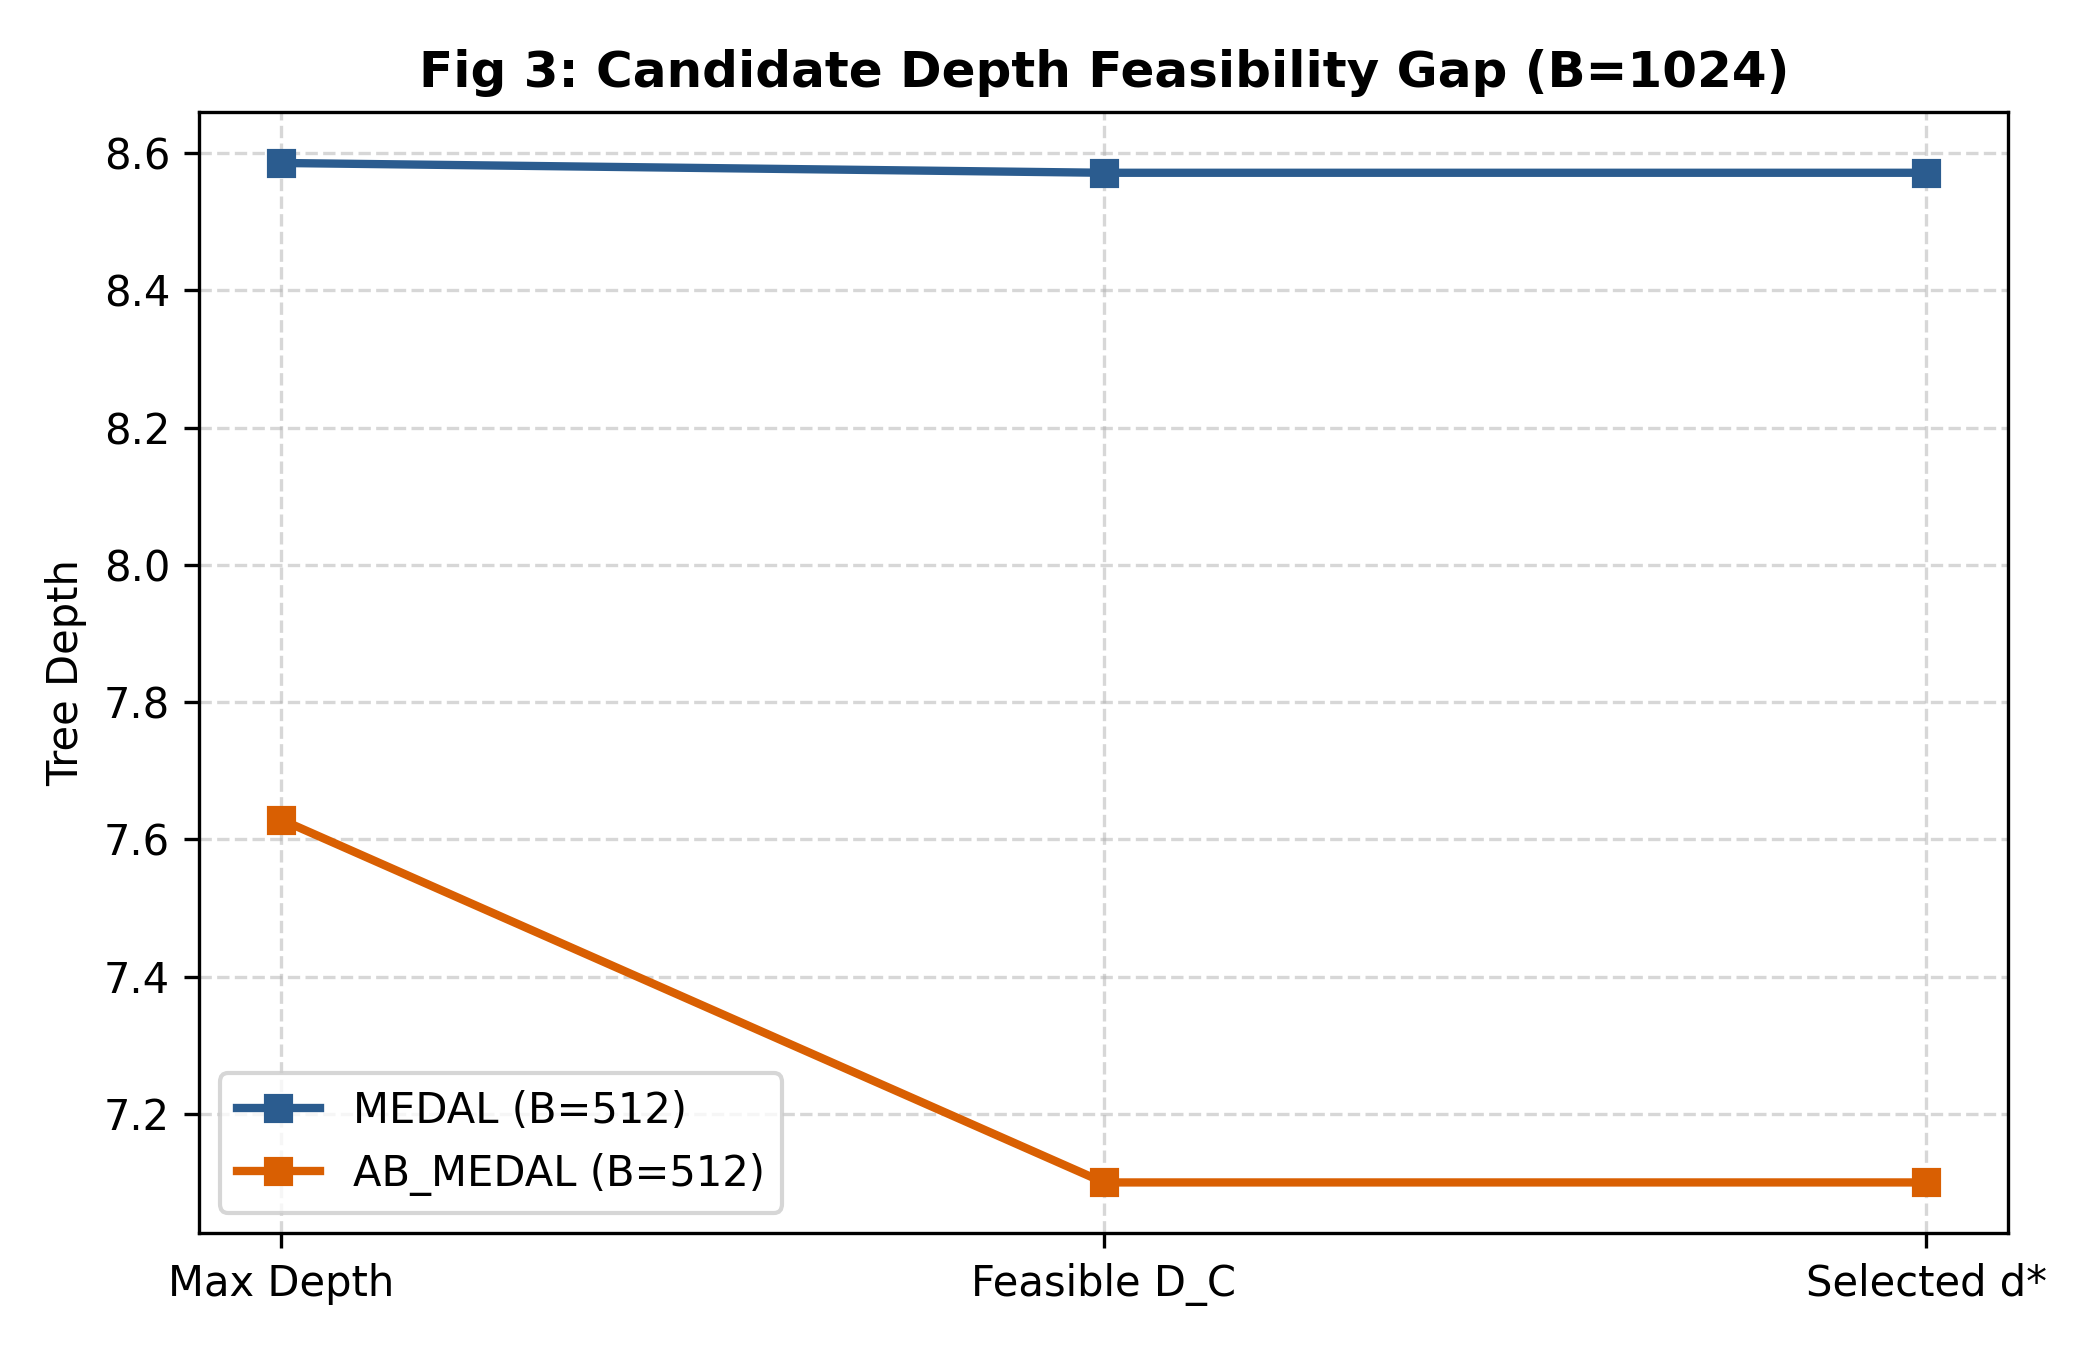

### Figure 4: Root-Subtree Compute Concentration — Search effort across root branches

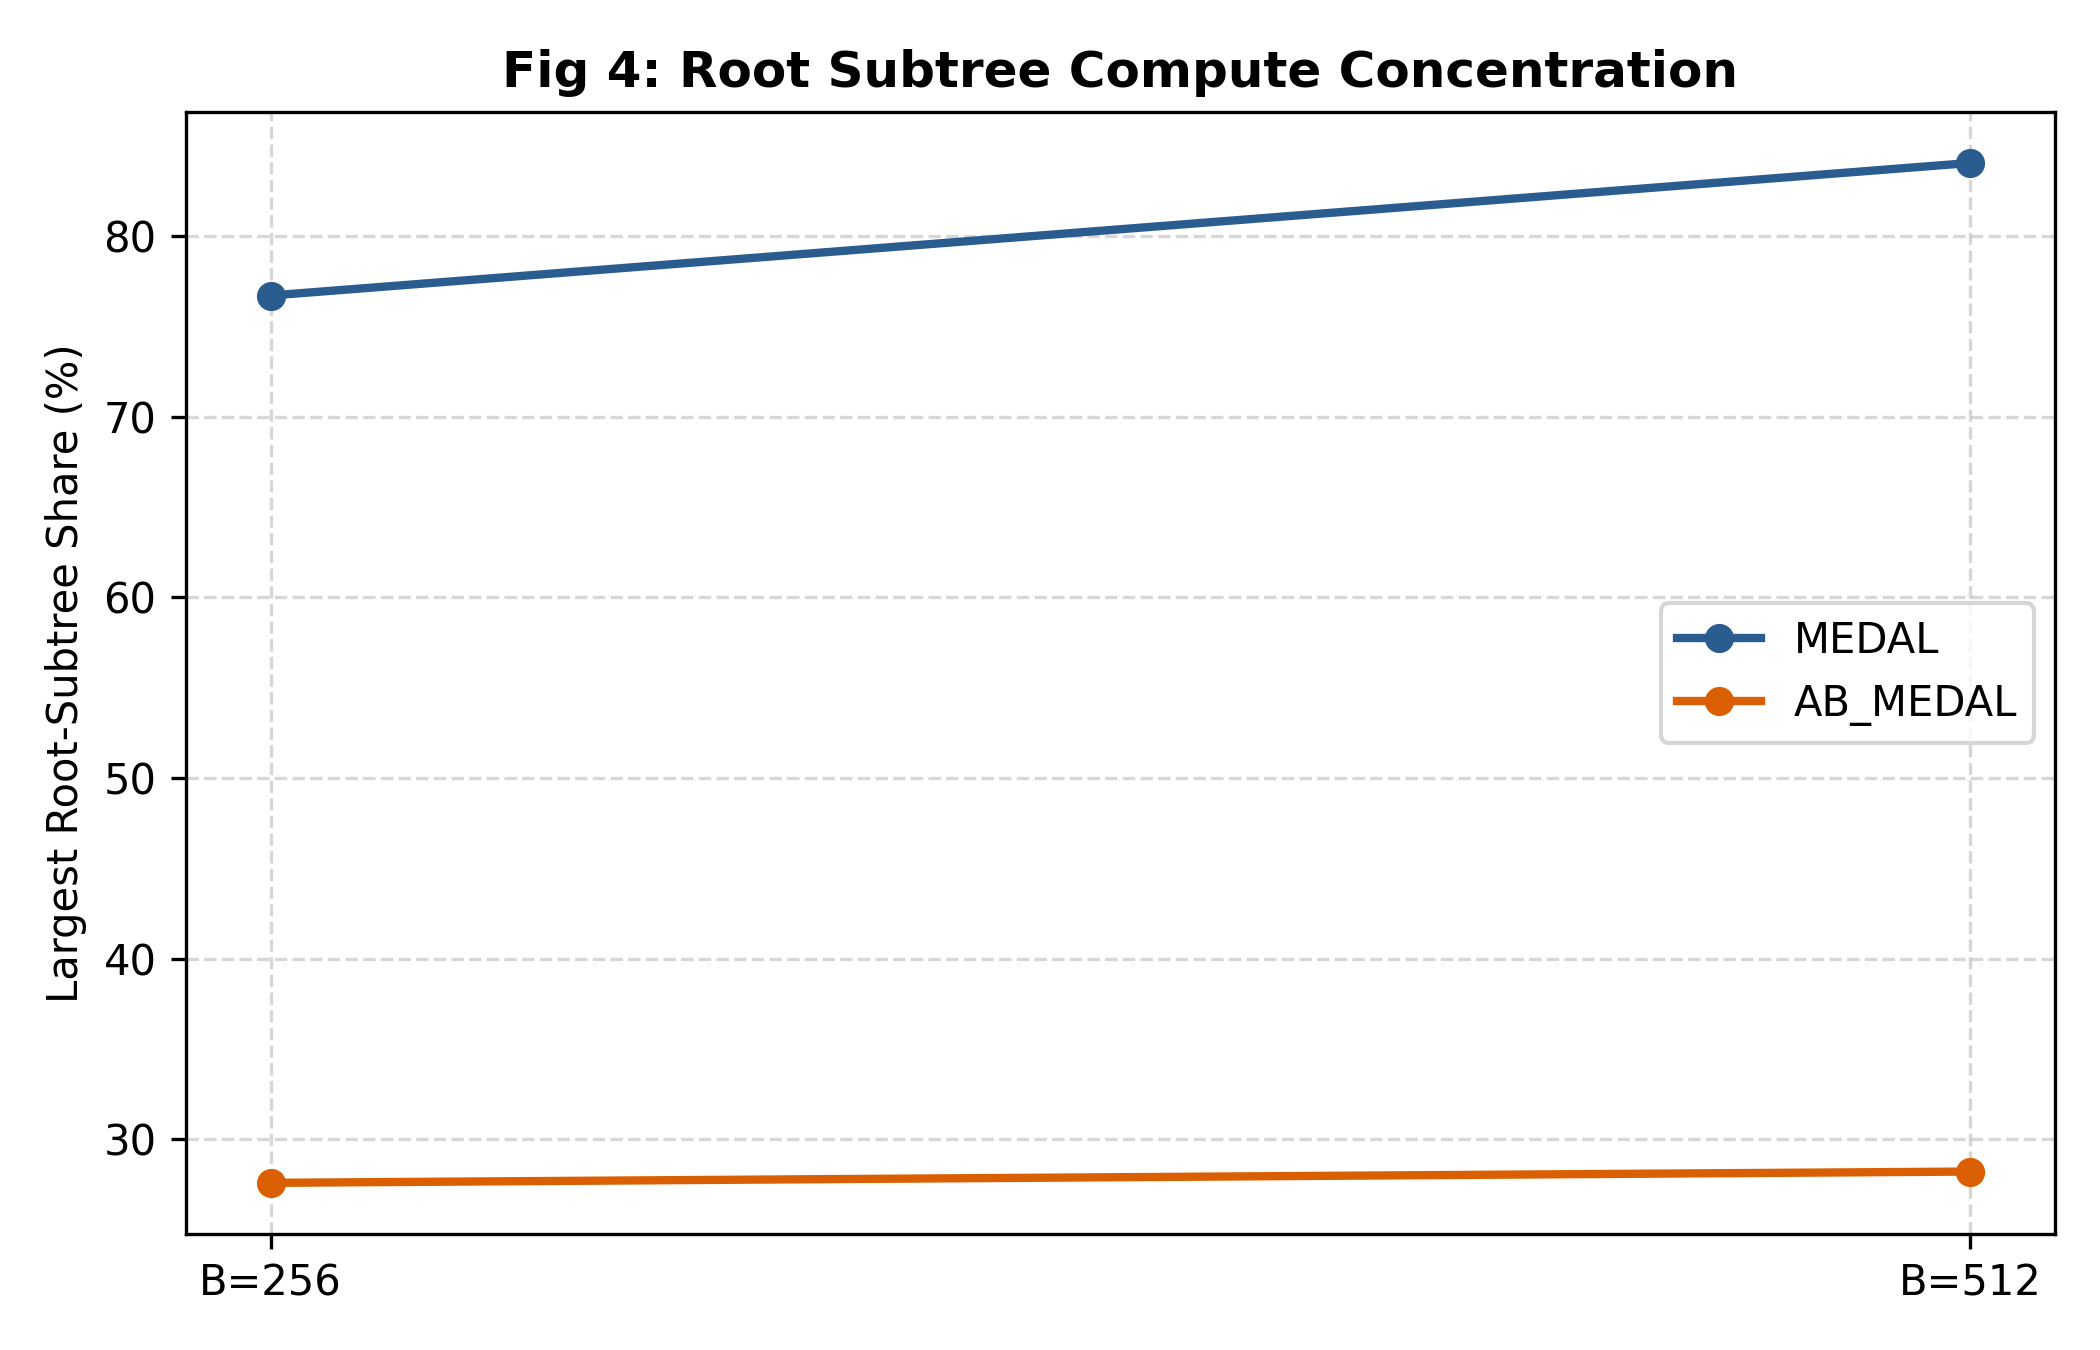

### Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states

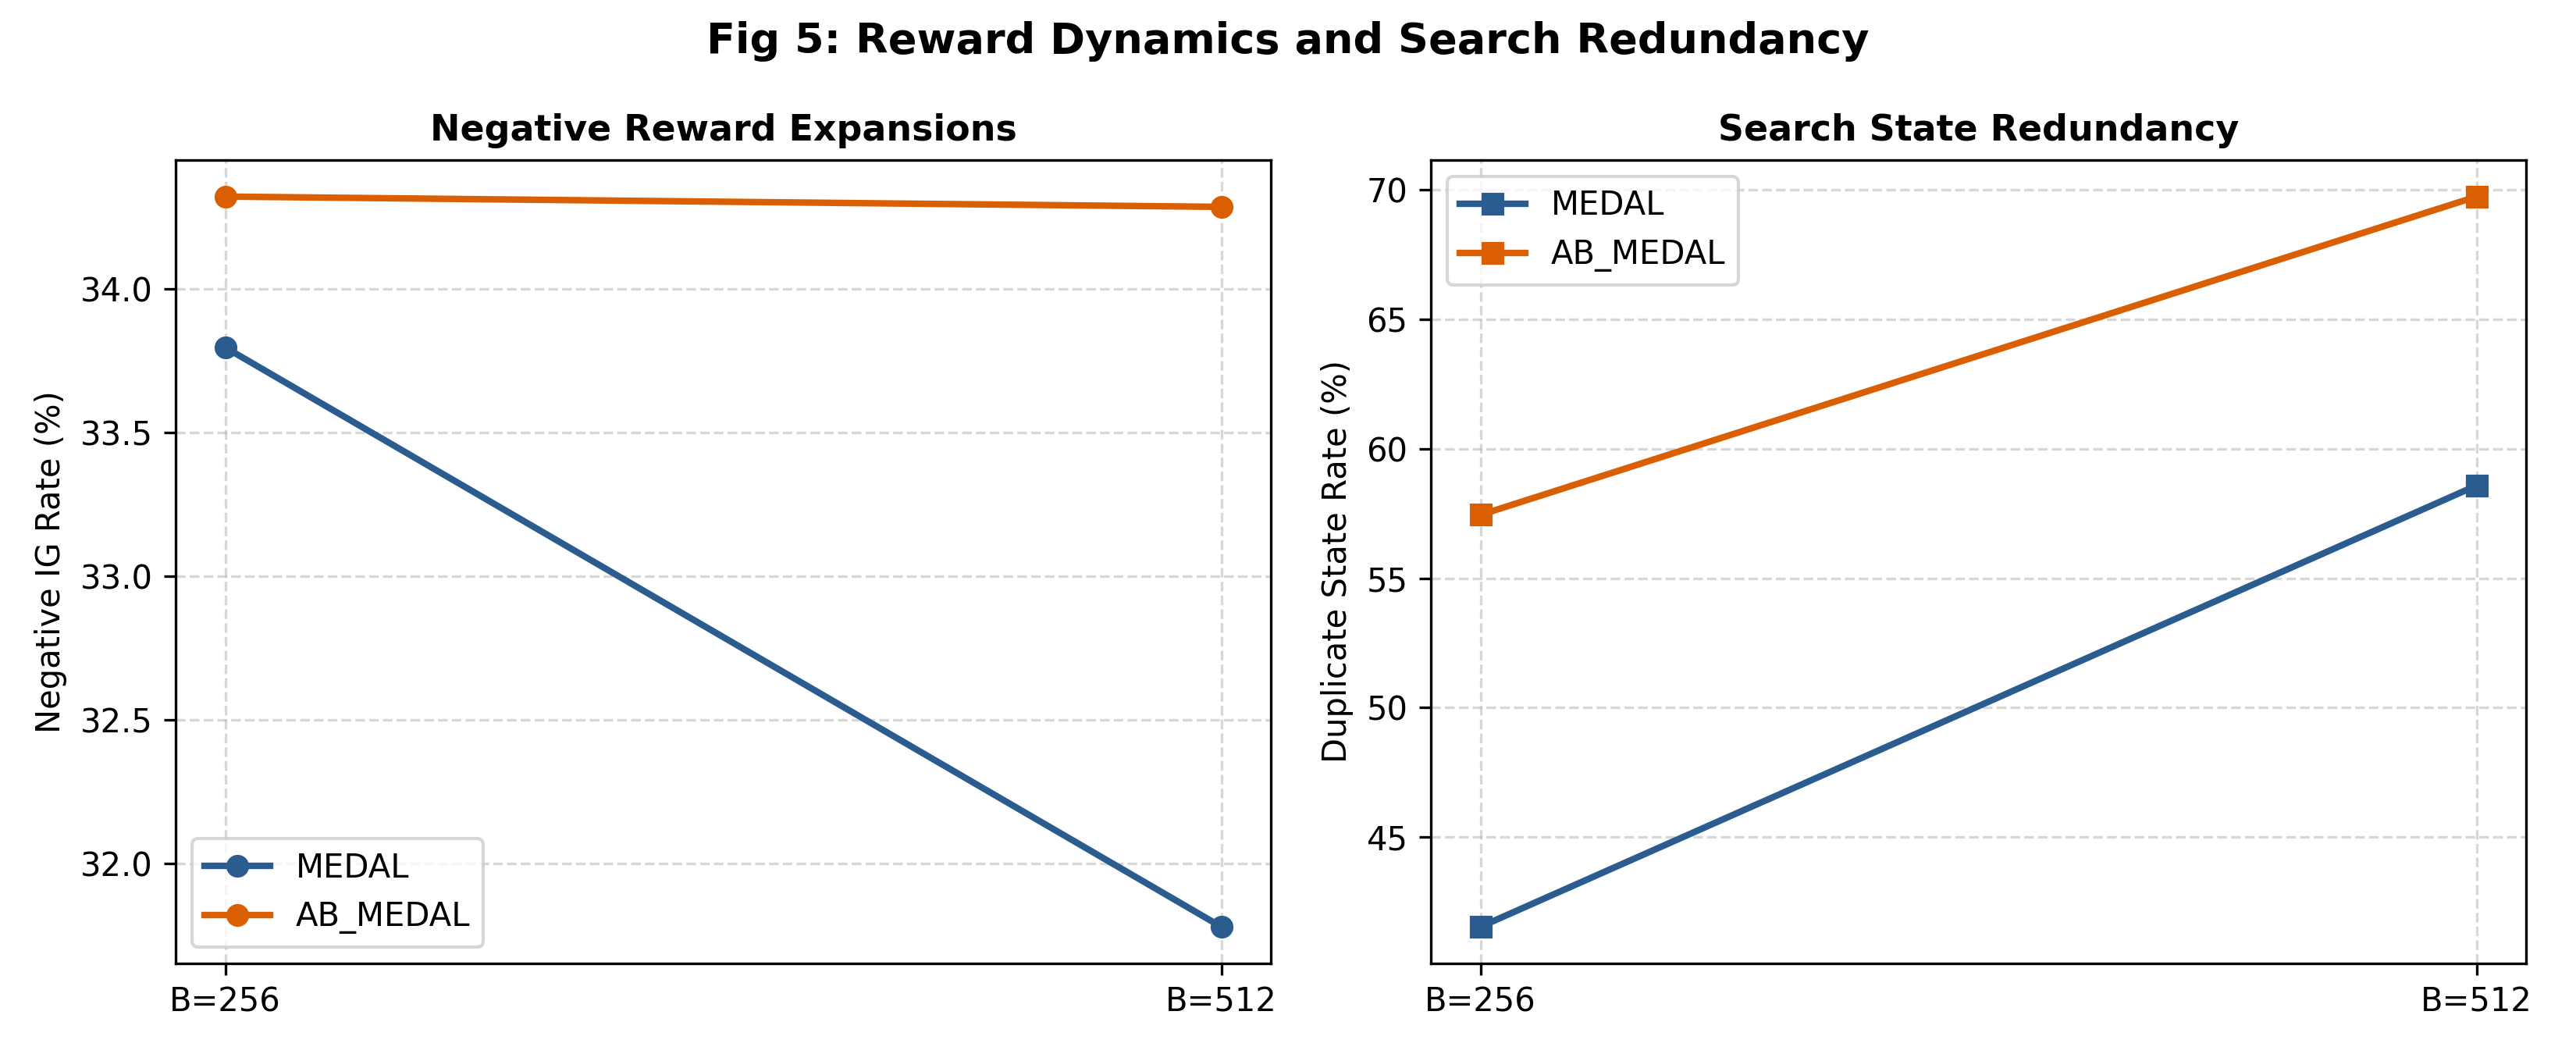

### Figure 6: Accuracy vs Search Budget — Performance scaling curve

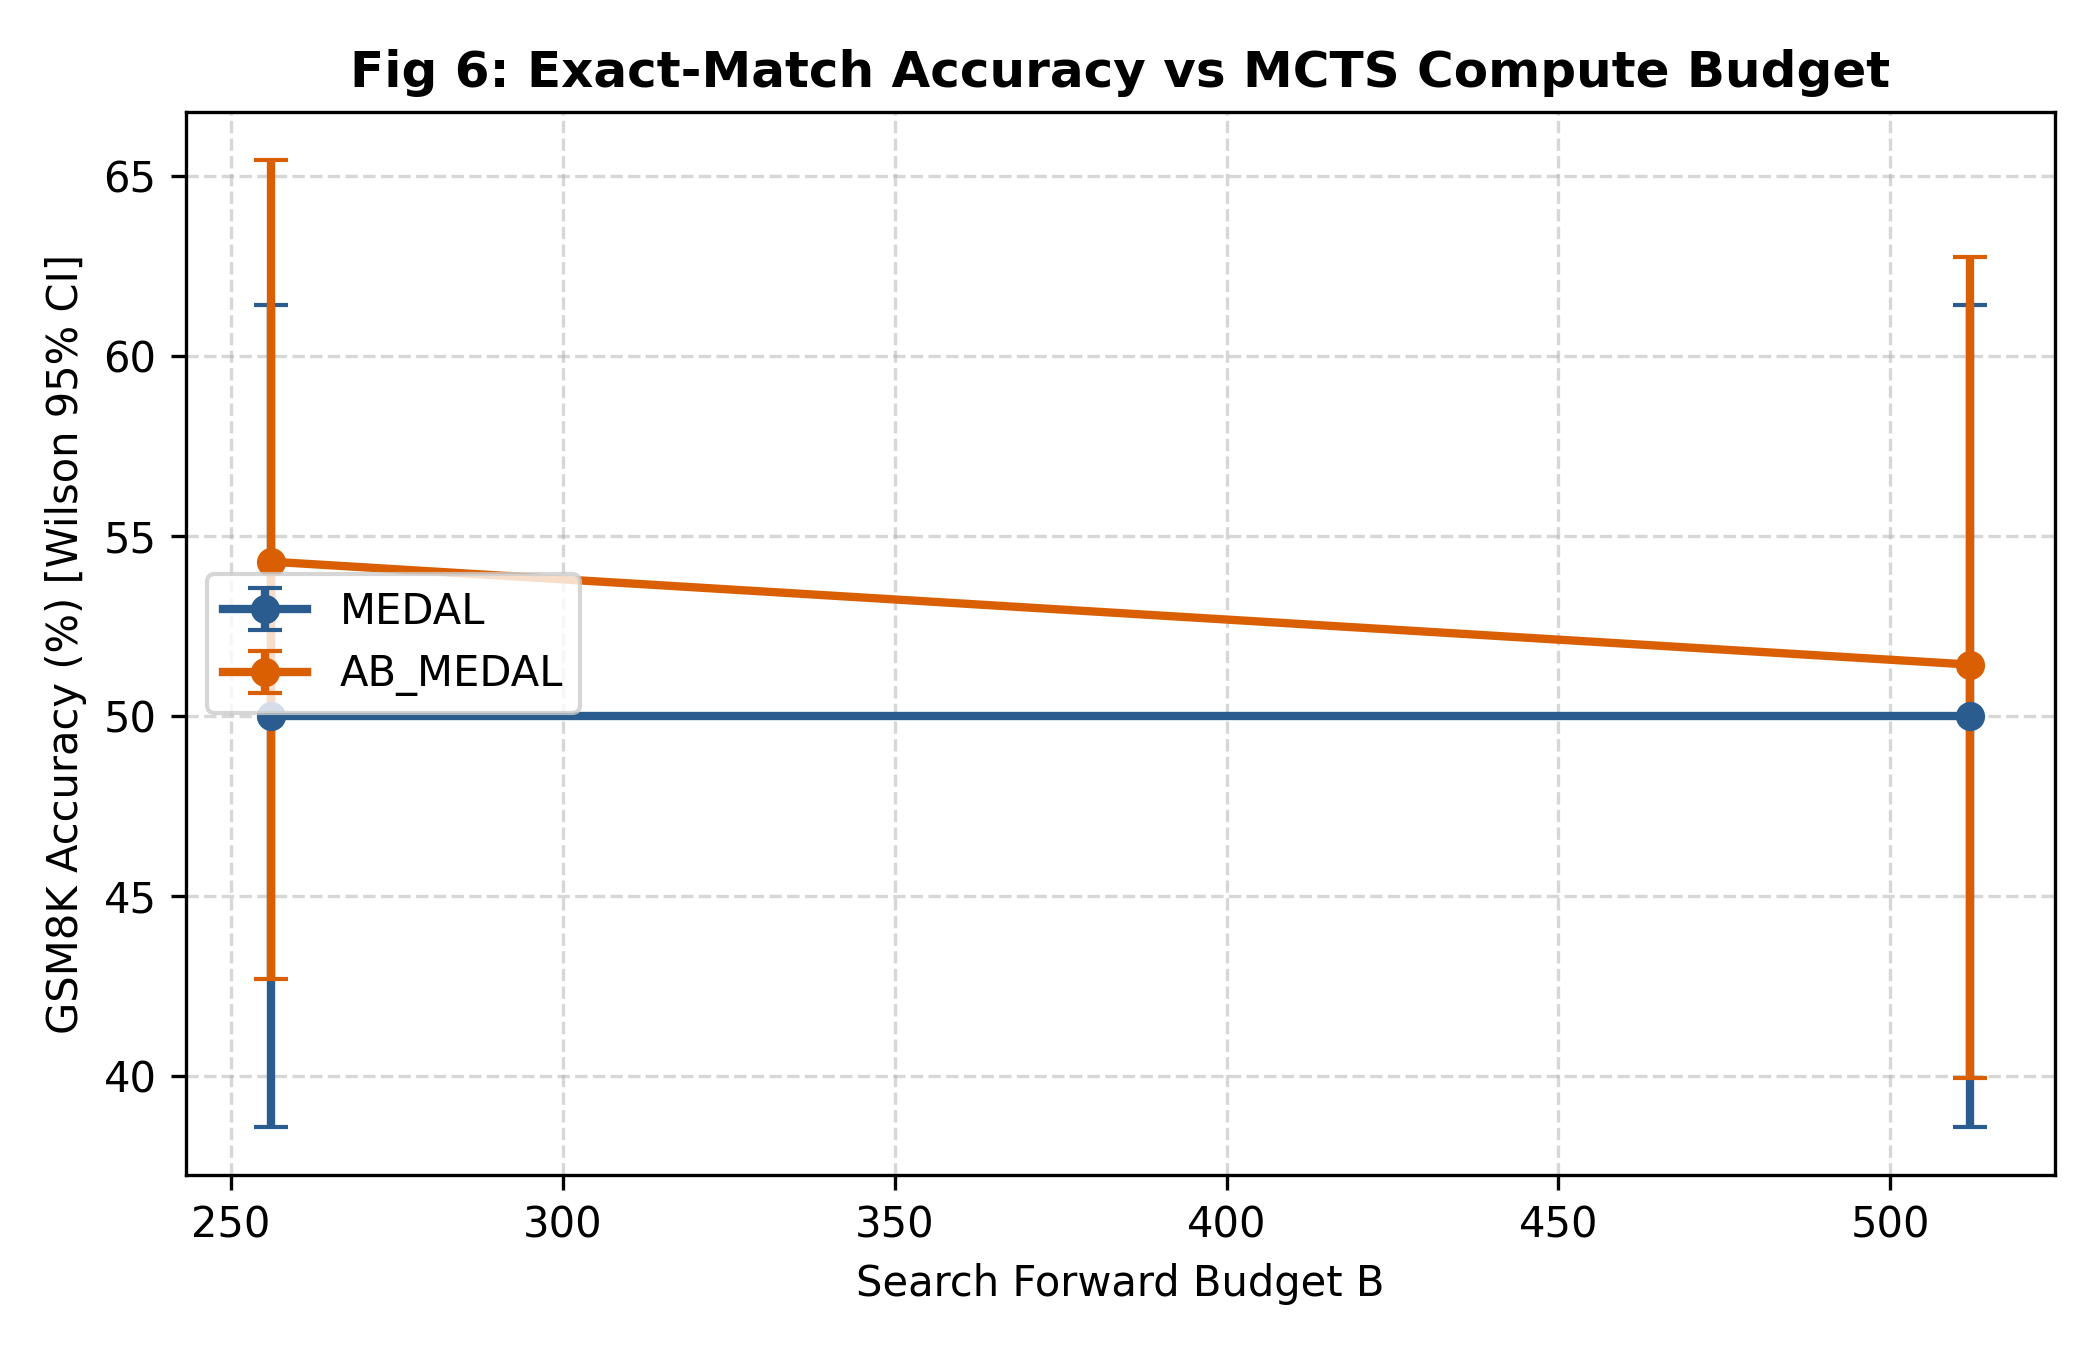

In [12]:
import shutil
from dlm_project.tasks.gsm8k.e3_analysis import analyze_e3_stage
from IPython.display import Image, display, Markdown

# Build combined trace directory linking canonical_20 and extended_50
combined_results_dir = OUTPUT_DIR / 'combined_70' / 'evaluation'
combined_results_dir.mkdir(parents=True, exist_ok=True)
for part_dir in [OUTPUT_DIR / 'canonical_20' / 'evaluation', OUTPUT_DIR / 'extended_50' / 'evaluation']:
    if part_dir.is_dir():
        for m in METHODS:
            m_src = part_dir / m
            if m_src.is_dir():
                m_dst = combined_results_dir / m
                m_dst.mkdir(parents=True, exist_ok=True)
                for q_dir in m_src.iterdir():
                    if q_dir.is_dir() and not (m_dst / q_dir.name).exists():
                        try:
                            (m_dst / q_dir.name).symlink_to(q_dir, target_is_directory=True)
                        except OSError:
                            shutil.copytree(q_dir, m_dst / q_dir.name)

# Select results directory: combined_70 if populated, else canonical_20
has_combined = any((combined_results_dir / m).is_dir() and any((combined_results_dir / m).iterdir()) for m in METHODS)
eval_results_dir = combined_results_dir if has_combined else (OUTPUT_DIR / 'canonical_20' / 'evaluation')
e3_output_dir = OUTPUT_DIR / ('combined_70' if has_combined else 'canonical_20') / 'summaries'
e3_output_dir.mkdir(parents=True, exist_ok=True)

print(f'Running E3 Offline Tree Analysis on {eval_results_dir}...')
e3_q, e3_agg = analyze_e3_stage(
    results_dir=eval_results_dir,
    output_dir=e3_output_dir,
    stage='evaluation',
    methods=tuple(METHODS),
    budgets=tuple(BUDGETS),
)
print(f'✓ E3 Analysis Completed successfully: {len(e3_q)} question outcomes evaluated.')

figures_dir = e3_output_dir / 'e3_figures'
fig_titles = {
    'fig1_nfe_by_depth': 'Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets',
    'fig2_branching_factors': 'Figure 2: Branching Factor Distribution — Children per expanded parent',
    'fig3_candidate_density': 'Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth',
    'fig4_root_subtrees': 'Figure 4: Root-Subtree Compute Concentration — Search effort across root branches',
    'fig5_reward_redundancy': 'Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states',
    'fig6_accuracy_vs_budget': 'Figure 6: Accuracy vs Search Budget — Performance scaling curve',
}

for fig_key, title in fig_titles.items():
    png_path = figures_dir / f'{fig_key}.png'
    if png_path.is_file():
        display(Markdown(f'### {title}'))
        display(Image(filename=str(png_path), width=750))


## 12. Synchronize All Artifacts to Google Drive
Flush and sync all in-flight buffers to Google Drive.

In [13]:
if IN_COLAB:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Google Drive flushed successfully.')


Google Drive flushed successfully.
